# Adverderial attacks for class imbalance lending default datasets

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

Loading the accepted lending dataset.

"This dataset contains the full LendingClub data available from their site. There are separate files for accepted and rejected loans. The accepted loans also include the FICO scores, which can only be downloaded when you are signed in to LendingClub and download the data." https://www.kaggle.com/datasets/wordsforthewise/lending-club

In [2]:
df = pd.read_csv("data/accepted.csv", low_memory=False)

## Section 1 exploring the dataset

In [3]:
print(f"Number of Records: {df.shape[0]:,.0f}")
print(f"Number of Features: {df.shape[1]}")

Number of Records: 2,260,701
Number of Features: 151


In [4]:
print("Columns:")
for col in df.columns:
    print(f" - {col}")

Columns:
 - id
 - member_id
 - loan_amnt
 - funded_amnt
 - funded_amnt_inv
 - term
 - int_rate
 - installment
 - grade
 - sub_grade
 - emp_title
 - emp_length
 - home_ownership
 - annual_inc
 - verification_status
 - issue_d
 - loan_status
 - pymnt_plan
 - url
 - desc
 - purpose
 - title
 - zip_code
 - addr_state
 - dti
 - delinq_2yrs
 - earliest_cr_line
 - fico_range_low
 - fico_range_high
 - inq_last_6mths
 - mths_since_last_delinq
 - mths_since_last_record
 - open_acc
 - pub_rec
 - revol_bal
 - revol_util
 - total_acc
 - initial_list_status
 - out_prncp
 - out_prncp_inv
 - total_pymnt
 - total_pymnt_inv
 - total_rec_prncp
 - total_rec_int
 - total_rec_late_fee
 - recoveries
 - collection_recovery_fee
 - last_pymnt_d
 - last_pymnt_amnt
 - next_pymnt_d
 - last_credit_pull_d
 - last_fico_range_high
 - last_fico_range_low
 - collections_12_mths_ex_med
 - mths_since_last_major_derog
 - policy_code
 - application_type
 - annual_inc_joint
 - dti_joint
 - verification_status_joint
 - acc_no

In [5]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing = df.isnull().sum()
missing

id                             0
member_id                2260701
loan_amnt                     33
funded_amnt                   33
funded_amnt_inv               33
                          ...   
settlement_status        2226455
settlement_date          2226455
settlement_amount        2226455
settlement_percentage    2226455
settlement_term          2226455
Length: 151, dtype: int64

We see a lot of nan values so lets drop the features that have a lot of NaN values

In [8]:
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': missing_percent
})

missing_table = missing_table.sort_values(by='Percentage (%)', ascending=False)
pd.set_option('display.max_rows', None)

missing_table

,Missing Values,Percentage (%)
member_id,2260701,100.000000
orig_projected_additional_accrued_interest,2252050,99.617331
hardship_end_date,2249784,99.517097
hardship_start_date,2249784,99.517097
hardship_type,2249784,99.517097
hardship_reason,2249784,99.517097
hardship_status,2249784,99.517097
deferral_term,2249784,99.517097
hardship_last_payment_amount,2249784,99.517097
hardship_payoff_balance_amount,2249784,99.517097


In [9]:
cols_to_drop = missing_table[missing_table['Percentage (%)'] > 50].index # Selects columsn with > 50% missing and returns their names

print("Columns to drop:")
for col in cols_to_drop:
    print(f" - {col}")

df = df.drop(columns=cols_to_drop, errors='ignore')

Columns to drop:
 - member_id
 - orig_projected_additional_accrued_interest
 - hardship_end_date
 - hardship_start_date
 - hardship_type
 - hardship_reason
 - hardship_status
 - deferral_term
 - hardship_last_payment_amount
 - hardship_payoff_balance_amount
 - hardship_loan_status
 - hardship_dpd
 - hardship_length
 - payment_plan_start_date
 - hardship_amount
 - settlement_term
 - debt_settlement_flag_date
 - settlement_status
 - settlement_date
 - settlement_amount
 - settlement_percentage
 - sec_app_mths_since_last_major_derog
 - sec_app_revol_util
 - revol_bal_joint
 - sec_app_mort_acc
 - sec_app_fico_range_low
 - sec_app_fico_range_high
 - sec_app_earliest_cr_line
 - sec_app_inq_last_6mths
 - sec_app_open_acc
 - sec_app_open_act_il
 - sec_app_num_rev_accts
 - sec_app_chargeoff_within_12_mths
 - sec_app_collections_12_mths_ex_med
 - verification_status_joint
 - dti_joint
 - annual_inc_joint
 - desc
 - mths_since_last_record
 - mths_since_recent_bc_dlq
 - mths_since_last_major_derog

In [10]:
df.shape

(2260701, 107)

Following the Kaggle notebooks we will keep the following collumns

| # | Feature | Description |
|---|---------|-------------|
| 0 | `loan_amnt` | The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value. |
| 1 | `term` | The number of payments on the loan. Values are in months and can be either 36 or 60. |
| 2 | `int_rate` | Interest Rate on the loan |
| 3 | `installment` | The monthly payment owed by the borrower if the loan originates. |
| 4 | `grade` | LC assigned loan grade |
| 5 | `sub_grade` | LC assigned loan subgrade |
| 6 | `emp_length` | Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years. |
| 7 | `home_ownership` | The home ownership status provided by the borrower during registration or obtained from the credit report. Values: RENT, OWN, MORTGAGE, OTHER |
| 8 | `annual_inc` | The self-reported annual income provided by the borrower during registration. |
| 9 | `verification_status` | Indicates if income was verified by LC, not verified, or if the income source was verified |
| 10 | `issue_d` | The month which the loan was funded |
| 11 | `loan_status` | Current status of the loan |
| 12 | `purpose` | A category provided by the borrower for the loan request. |
| 13 | `title` | The loan title provided by the borrower |
| 14 | `zip_code` | The first 3 numbers of the zip code provided by the borrower in the loan application. |
| 15 | `addr_state` | The state provided by the borrower in the loan application |
| 16 | `dti` | A ratio calculated using the borrower's total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower's self-reported monthly income. |
| 17 | `earliest_cr_line` | The month the borrower's earliest reported credit line was opened |
| 18 | `open_acc` | The number of open credit lines in the borrower's credit file. |
| 19 | `pub_rec` | Number of derogatory public records |
| 20 | `revol_bal` | Total credit revolving balance |
| 21 | `revol_util` | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| 22 | `total_acc` | The total number of credit lines currently in the borrower's credit file |
| 23 | `initial_list_status` | The initial listing status of the loan. Possible values are W, F |
| 24 | `application_type` | Indicates whether the loan is an individual application or a joint application with two co-borrowers |
| 25 | `mort_acc` | Number of mortgage accounts. |
| 26 | `pub_rec_bankruptcies` | Number of public record bankruptcies. |

In [11]:
df = df[[
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
    'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
    'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status',
    'application_type', 'mort_acc', 'pub_rec_bankruptcies'
]]

In [12]:
df.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
count,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06,2.260639e+06,2.260668e+06,2.260668e+06,2.260638e+06,2.260639e+06,2.260639e+06,2.260668e+06,2.258866e+06,2.260639e+06,2.210638e+06,2.259303e+06
mean,1.504693e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01,3.068792e-01,6.985882e+02,7.025884e+02,5.768354e-01,1.161240e+01,1.975278e-01,1.665846e+04,5.033770e+01,2.416255e+01,1.555382e+00,1.281935e-01
std,9.190245e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01,8.672303e-01,3.301038e+01,3.301124e+01,8.859632e-01,5.640861e+00,5.705150e-01,2.294831e+04,2.471307e+01,1.198753e+01,1.904981e+00,3.646130e-01
min,5.000000e+02,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.100000e+02,6.140000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01,0.000000e+00,6.750000e+02,6.790000e+02,0.000000e+00,8.000000e+00,0.000000e+00,5.950000e+03,3.150000e+01,1.500000e+01,0.000000e+00,0.000000e+00
50%,1.290000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01,0.000000e+00,6.900000e+02,6.940000e+02,0.000000e+00,1.100000e+01,0.000000e+00,1.132400e+04,5.030000e+01,2.200000e+01,1.000000e+00,0.000000e+00
75%,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01,0.000000e+00,7.150000e+02,7.190000e+02,1.000000e+00,1.400000e+01,0.000000e+00,2.024600e+04,6.940000e+01,3.100000e+01,3.000000e+00,0.000000e+00
max,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02,5.800000e+01,8.450000e+02,8.500000e+02,3.300000e+01,1.010000e+02,8.600000e+01,2.904836e+06,8.923000e+02,1.760000e+02,9.400000e+01,1.200000e+01


In [14]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
loan_status              object
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

We Want to predict the rate of default so we wil rename it to target

In [15]:
df = df.rename(columns={"loan_status": "target"})
df["target"] = df["target"].map({"Charged Off": 1, "Fully Paid": 0})


# Visualisation of the dataset

In [16]:
df.groupby("target").count()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
target,,,,,,,,,,,,,,,,,,,,,
0.0,1076751,1076751,1076751,1076751,1076751,1076751,1019370,1076751,1076751,1076751,...,1076750,1076751,1076751,1076751,1076074,1076751,1076751,1076751,1036356,1076172
1.0,268559,268559,268559,268559,268559,268559,247429,268559,268559,268559,...,268559,268559,268559,268559,268379,268559,268559,268559,261673,268441


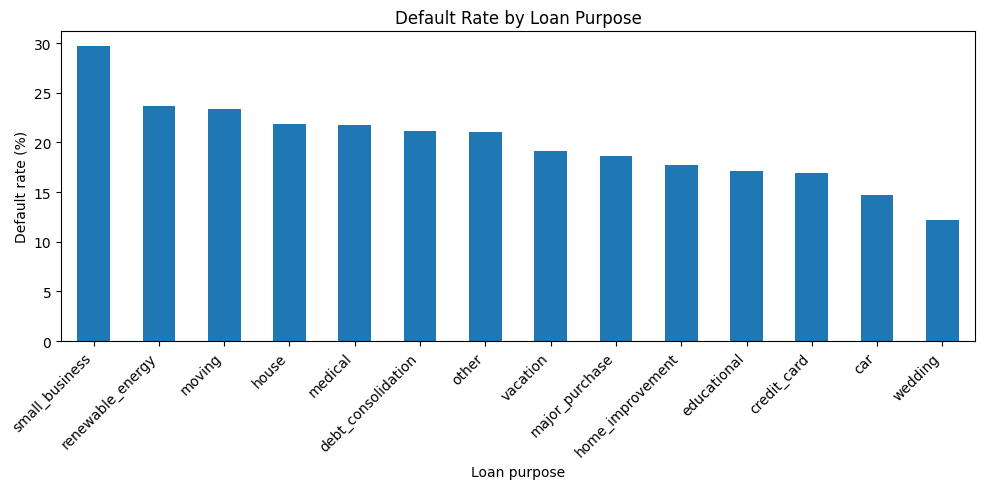

In [17]:
purpose_default_rate = (
    df.groupby("purpose")["target"].mean().sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

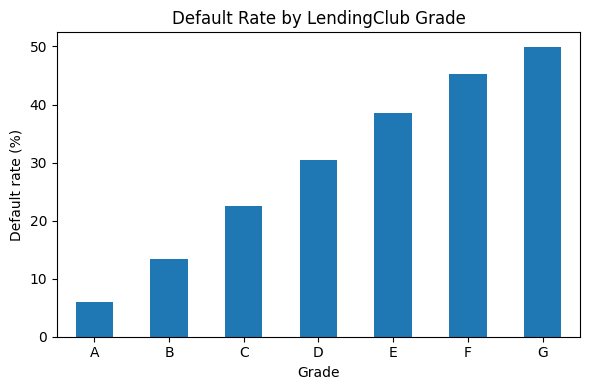

In [18]:
grade_default_rate = (
    df
    .groupby("grade")["target"]
    .mean()
    .sort_index() * 100
)

plt.figure(figsize=(6, 4))
grade_default_rate.plot(kind="bar")

plt.title("Default Rate by LendingClub Grade")
plt.xlabel("Grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

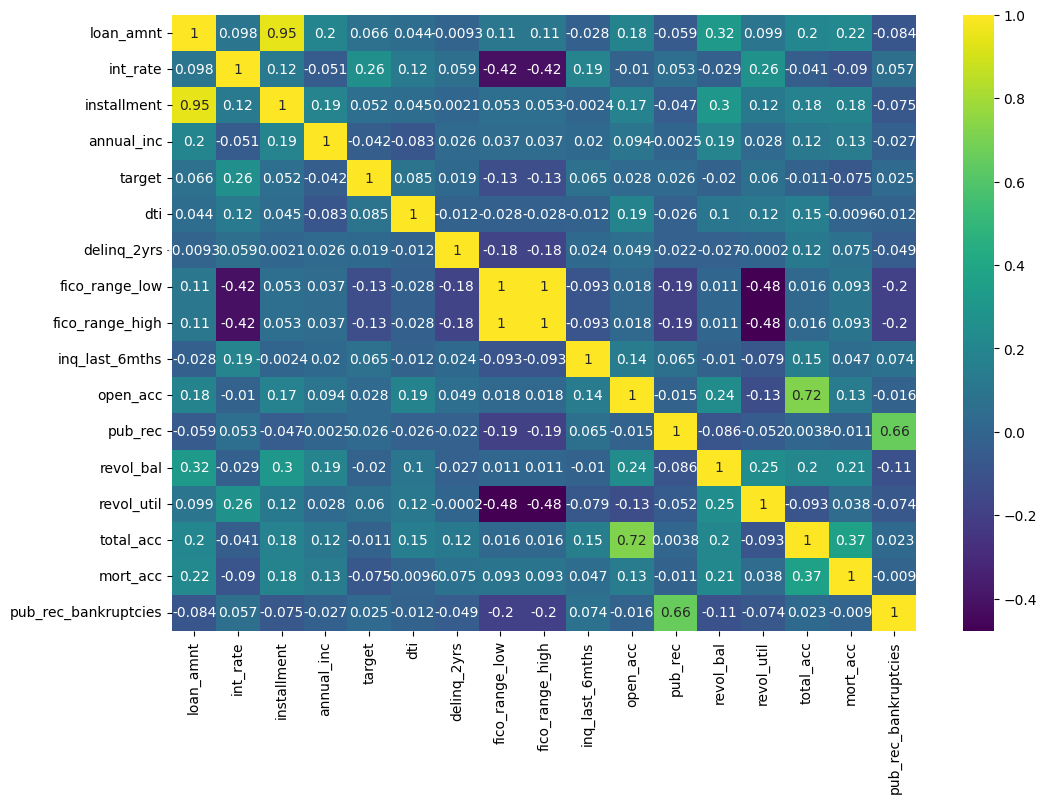

In [19]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='viridis')
plt.show()

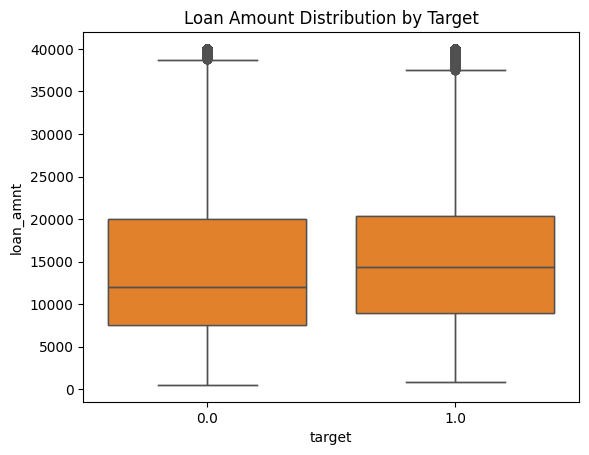

In [21]:
boxplot = sns.boxplot(x="target", y="loan_amnt", data=df)
boxplot.set_title("Loan Amount Distribution by Target")
plt.show()

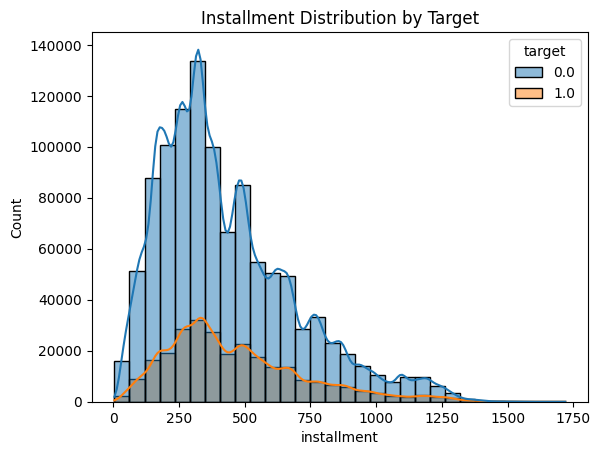

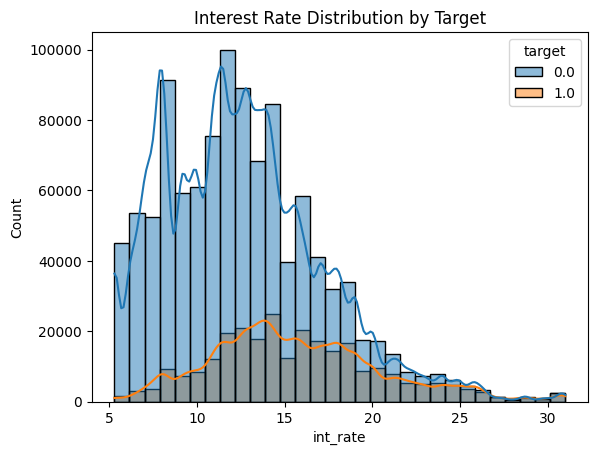

In [23]:
installment = sns.histplot(data=df, x="installment", hue="target", kde=True, bins=30)
installment.set_title("Installment Distribution by Target")

plt.show()

interest_rate = sns.histplot(data=df, x="int_rate", hue="target", kde=True, bins=30)
interest_rate.set_title("Interest Rate Distribution by Target")

plt.show()

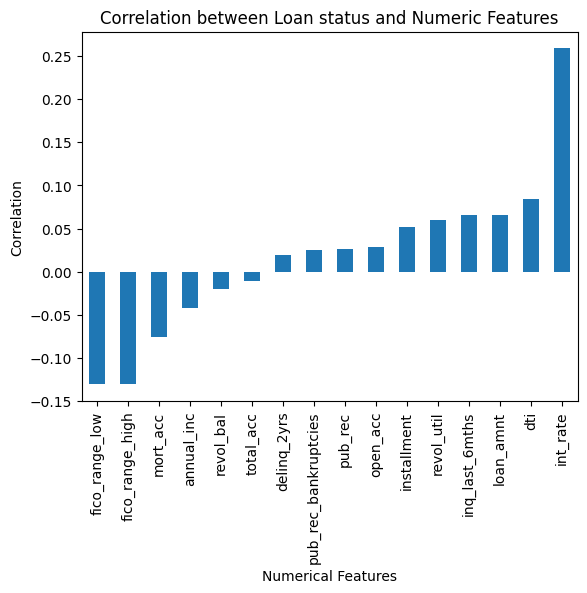

In [27]:
df.corr(numeric_only=True)['target'].drop('target').sort_values().plot(kind='bar',
    title="Correlation between Loan status and Numeric Features", 
    ylabel='Correlation', xlabel='Numerical Features', 
)
plt.show()

## DPT

### Convert categorical features into numereric

In [29]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
target                  float64
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

In [32]:
df.application_type.unique()

array(['Individual', 'Joint App', nan], dtype=object)

Since application type is just two values we binary encode

In [35]:
df['Individual application'] = df['application_type'] == 'INDIVIDUAL'
df.drop(columns=['application_type'], inplace=True)

In [33]:
df.emp_length.unique()

array(['10+ years', '3 years', '4 years', '6 years', '1 year', '7 years',
       '8 years', '5 years', '2 years', '9 years', '< 1 year', nan],
      dtype=object)

employement length we can ordinal encode

In [34]:
df["emp_length"] = df["emp_length"].map({"<1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10})

In [39]:
df.term.value_counts()

term
 36 months    1609754
 60 months     650914
36 months          33
Name: count, dtype: int64

For term we kan strip the months and convert to int

In [ ]:
df["term"].fillna("36 months", inplace=True)

In [40]:
df["term"] = df["term"].str.strip().str.replace(" months", "").astype(int)

In [42]:
df.purpose.value_counts().head()

purpose
debt_consolidation    1277877
credit_card            516971
home_improvement       150457
other                  139440
major_purchase          50445
Name: count, dtype: int64

In [43]:
df['verification_status'].value_counts()

verification_status
Source Verified    886231
Not Verified       744806
Verified           629631
Name: count, dtype: int64

In [44]:
df['initial_list_status'].value_counts()

initial_list_status
w    1535467
f     725201
Name: count, dtype: int64

In [45]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    1111450
RENT         894929
OWN          253057
ANY             996
OTHER           182
NONE             54
Name: count, dtype: int64

We also know subgrade is a more detailed version of grade, so we can drop grade.

In [46]:
df.drop('grade', axis=1, inplace=True)

dummies = ['sub_grade', 'verification_status', 'purpose', 'initial_list_status', 'home_ownership']
df = pd.get_dummies(df, columns=dummies, drop_first=True)



In [47]:
df.dtypes

loan_amnt                              float64
term                                     int32
int_rate                               float64
installment                            float64
emp_length                             float64
annual_inc                             float64
issue_d                                 object
target                                 float64
addr_state                              object
dti                                    float64
delinq_2yrs                            float64
earliest_cr_line                        object
fico_range_low                         float64
fico_range_high                        float64
inq_last_6mths                         float64
open_acc                               float64
pub_rec                                float64
revol_bal                              float64
revol_util                             float64
total_acc                              float64
mort_acc                               float64
pub_rec_bankr

We need to drop issue date since it is data leakage as the model would no know if the loan has been approved or not before making its prediction

In [48]:
df.drop('issue_d', axis=1, inplace=True)



Fill missing values

In [49]:
df.isnull().sum()

loan_amnt                                  33
term                                        0
int_rate                                   33
installment                                33
emp_length                             336928
annual_inc                                 37
target                                 915391
addr_state                                 33
dti                                      1744
delinq_2yrs                                62
earliest_cr_line                           62
fico_range_low                             33
fico_range_high                            33
inq_last_6mths                             63
open_acc                                   62
pub_rec                                    62
revol_bal                                  33
revol_util                               1835
total_acc                                  62
mort_acc                                50063
pub_rec_bankruptcies                     1398
Individual application            